EJERCICIO A1: SILLAS Y MESAS

--- PASO 1: MODELO MATEMÁTICO ---
Variables de decisión:
  x1 = número de sillas a producir
  x2 = número de mesas a producir

Función objetivo:
  max z = 30*x1 + 50*x2

Restricciones:
  2*x1 + 4*x2 <= 40  (carpintería)
  3*x1 + 1*x2 <= 30  (pintura)
  x1, x2 >= 0

--- PASO 2: FORMA ESTÁNDAR ---
Se agregan variables de holgura s1, s2 >= 0:
  2*x1 + 4*x2 + s1 = 40
  3*x1 + 1*x2 + s2 = 30
  z - 30*x1 - 50*x2 = 0

Base inicial: {s1, s2} -> solución (x1=0, x2=0, z=0)

--- PASO 3: TABLA SIMPLEX PASO A PASO ---

Iteración 0 (inicial)
Base          x1      x2      s1      s2       Sol
--------------------------------------------------
s1          2.00    4.00    1.00    0.00   40.00
s2          3.00    1.00    0.00    1.00   30.00
z         -30.00  -50.00    0.00    0.00    0.00

>>> Iteración 1: entra x2 (coef -50), sale s1 (razón 40/4=10 vs 30/1=30)

Iteración 1
Base          x1      x2      s1      s2       Sol
-------------------------------------------------

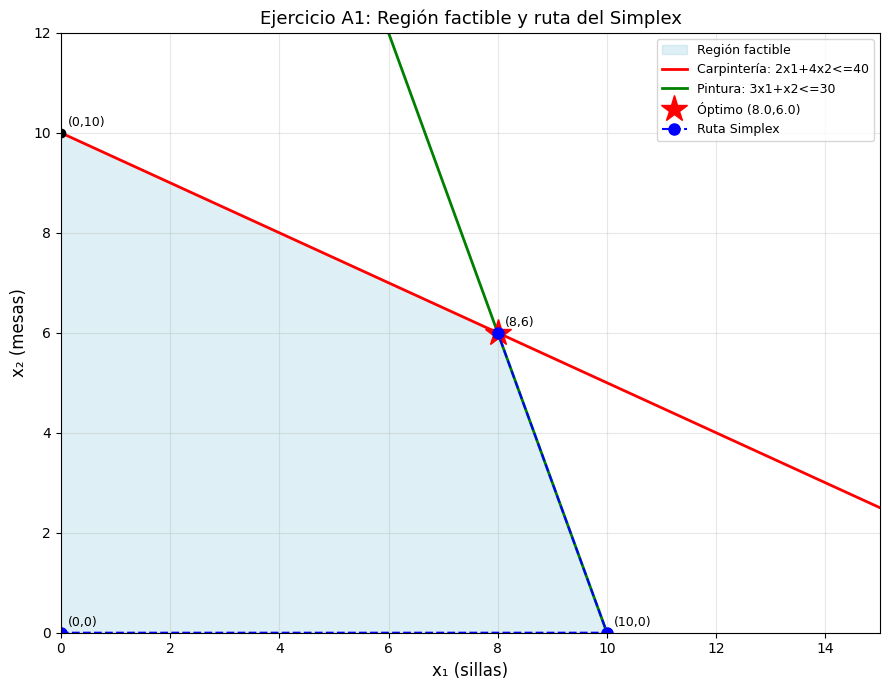


--- PASO 6: ANÁLISIS DE SENSIBILIDAD ---
Precios sombra (de la fila z de la tabla final):
  y1 (carpintería) = 12.00 $/hora
  y2 (pintura)     = 2.00 $/hora

Interpretación:
  Cada hora extra de carpintería aumenta la ganancia en $12
  Cada hora extra de pintura aumenta la ganancia en $2

Holguras en el óptimo:
  s1 = 0 (carpintería agotada)
  s2 = 0 (pintura agotada)

--- PASO 7: CONCLUSIONES ---
1. La solución óptima es producir 8 sillas y 6 mesas.
2. La ganancia máxima es $540.
3. Ambos recursos (carpintería y pintura) se agotan.
4. La ruta del Simplex visita los vértices (0,0) -> (10,0) -> (8,6).
5. El precio sombra de la carpintería ($12) es mayor que el de
   la pintura ($2), así que conviene invertir primero en más
   horas de carpintería.


In [1]:
# =====================================================================
# EJERCICIO A1 (SENCILLO): Maximización con restricciones <=
# =====================================================================
# PROBLEMA:
#   Una fábrica produce sillas (x1) y mesas (x2).
#   Ganancia: $30 por silla, $50 por mesa.
#   Restricciones:
#     2x1 + 4x2 <= 40  (horas de carpintería)
#     3x1 + x2  <= 30  (horas de pintura)
#
# OBJETIVO: maximizar la ganancia total.
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("="*70)
print("EJERCICIO A1: SILLAS Y MESAS")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: MODELO MATEMÁTICO
# ---------------------------------------------------------------------
print("\n--- PASO 1: MODELO MATEMÁTICO ---")
print("Variables de decisión:")
print("  x1 = número de sillas a producir")
print("  x2 = número de mesas a producir")
print("\nFunción objetivo:")
print("  max z = 30*x1 + 50*x2")
print("\nRestricciones:")
print("  2*x1 + 4*x2 <= 40  (carpintería)")
print("  3*x1 + 1*x2 <= 30  (pintura)")
print("  x1, x2 >= 0")

# ---------------------------------------------------------------------
# PASO 2: FORMA ESTÁNDAR (agregar holguras)
# ---------------------------------------------------------------------
print("\n--- PASO 2: FORMA ESTÁNDAR ---")
print("Se agregan variables de holgura s1, s2 >= 0:")
print("  2*x1 + 4*x2 + s1 = 40")
print("  3*x1 + 1*x2 + s2 = 30")
print("  z - 30*x1 - 50*x2 = 0")
print("\nBase inicial: {s1, s2} -> solución (x1=0, x2=0, z=0)")

# ---------------------------------------------------------------------
# PASO 3: TABLA SIMPLEX PASO A PASO (manual)
# ---------------------------------------------------------------------
print("\n--- PASO 3: TABLA SIMPLEX PASO A PASO ---")

# Tabla inicial: [x1, x2, s1, s2, sol]
tabla = np.array([
    [2, 4, 1, 0, 40],   # s1
    [3, 1, 0, 1, 30],   # s2
    [-30, -50, 0, 0, 0] # z
], dtype=float)

def imprimir_tabla(t, titulo):
    print(f"\n{titulo}")
    print(f"{'Base':<8}{'x1':>8}{'x2':>8}{'s1':>8}{'s2':>8}{'Sol':>10}")
    print("-"*50)
    for i, fila in enumerate(t):
        base = ['s1', 's2', 'z'][i]
        print(f"{base:<8}", end="")
        for v in fila:
            print(f"{v:>8.2f}", end="")
        print()

imprimir_tabla(tabla, "Iteración 0 (inicial)")

# --- Iteración 1: entra x2 (más negativo: -50), sale s1 ---
print("\n>>> Iteración 1: entra x2 (coef -50), sale s1 (razón 40/4=10 vs 30/1=30)")
pivote = tabla[0, 1]  # 4
tabla[0] = tabla[0] / pivote
for i in [1, 2]:
    tabla[i] = tabla[i] - tabla[i, 1] * tabla[0]
imprimir_tabla(tabla, "Iteración 1")

# --- Iteración 2: entra x1 (más negativo: -5), sale s2 ---
print("\n>>> Iteración 2: entra x1 (coef -5), sale s2 (razón 10/0.5=20 vs 20/2.5=8)")
pivote = tabla[1, 0]  # 2.5
tabla[1] = tabla[1] / pivote
for i in [0, 2]:
    tabla[i] = tabla[i] - tabla[i, 0] * tabla[1]
imprimir_tabla(tabla, "Iteración 2 (ÓPTIMA)")

print("\n>>> Todos los costos reducidos >= 0 -> SOLUCIÓN ÓPTIMA")
print(f"  x1 = {tabla[1, 4]:.2f} sillas")
print(f"  x2 = {tabla[0, 4]:.2f} mesas")
print(f"  z  = {tabla[2, 4]:.2f} dólares")

# ---------------------------------------------------------------------
# PASO 4: VERIFICACIÓN CON LINPROG
# ---------------------------------------------------------------------
print("\n--- PASO 4: VERIFICACIÓN CON SCIPY ---")
c = [-30, -50]
A_ub = [[2, 4], [3, 1]]
b_ub = [40, 30]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
print(f"  x1 = {res.x[0]:.4f}")
print(f"  x2 = {res.x[1]:.4f}")
print(f"  z  = {-res.fun:.4f}")

# ---------------------------------------------------------------------
# PASO 5: GRÁFICO DE LA REGIÓN FACTIBLE
# ---------------------------------------------------------------------
print("\n--- PASO 5: GRÁFICO ---")

fig, ax = plt.subplots(figsize=(9, 7))

# Vértices de la región factible
vertices = [(0, 0), (10, 0), (8, 6), (0, 10)]
verts = np.array(vertices)
ax.fill(verts[:, 0], verts[:, 1], color='lightblue', alpha=0.4,
        label='Región factible')

# Restricciones
x = np.linspace(0, 15, 400)
ax.plot(x, (40 - 2*x)/4, 'r-', linewidth=2,
        label='Carpintería: 2x1+4x2<=40')
ax.plot(x, (30 - 3*x)/1, 'g-', linewidth=2,
        label='Pintura: 3x1+x2<=30')

# Vértices
for v in vertices:
    ax.plot(v[0], v[1], 'ko', markersize=6)
    ax.annotate(f"({v[0]},{v[1]})", v, textcoords="offset points",
                xytext=(5, 5), fontsize=9)

# Óptimo
ax.plot(res.x[0], res.x[1], 'r*', markersize=20,
        label=f'Óptimo ({res.x[0]:.1f},{res.x[1]:.1f})')

# Ruta del Simplex
ax.plot([0, 10, 8], [0, 0, 6], 'b--o', linewidth=1.5,
        markersize=8, label='Ruta Simplex')

ax.set_xlim(0, 15)
ax.set_ylim(0, 12)
ax.set_xlabel('x₁ (sillas)', fontsize=12)
ax.set_ylabel('x₂ (mesas)', fontsize=12)
ax.set_title('Ejercicio A1: Región factible y ruta del Simplex',
             fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 6: ANÁLISIS DE SENSIBILIDAD
# ---------------------------------------------------------------------
print("\n--- PASO 6: ANÁLISIS DE SENSIBILIDAD ---")
print("Precios sombra (de la fila z de la tabla final):")
print(f"  y1 (carpintería) = {tabla[2, 2]:.2f} $/hora")
print(f"  y2 (pintura)     = {tabla[2, 3]:.2f} $/hora")
print("\nInterpretación:")
print("  Cada hora extra de carpintería aumenta la ganancia en $12")
print("  Cada hora extra de pintura aumenta la ganancia en $2")
print("\nHolguras en el óptimo:")
print(f"  s1 = 0 (carpintería agotada)")
print(f"  s2 = 0 (pintura agotada)")

# ---------------------------------------------------------------------
# PASO 7: CONCLUSIONES
# ---------------------------------------------------------------------
print("\n--- PASO 7: CONCLUSIONES ---")
print("1. La solución óptima es producir 8 sillas y 6 mesas.")
print("2. La ganancia máxima es $540.")
print("3. Ambos recursos (carpintería y pintura) se agotan.")
print("4. La ruta del Simplex visita los vértices (0,0) -> (10,0) -> (8,6).")
print("5. El precio sombra de la carpintería ($12) es mayor que el de")
print("   la pintura ($2), así que conviene invertir primero en más")
print("   horas de carpintería.")
print("="*70)